# 02 — Baseline Dataset EDA (`cardsim_base.parquet`)

Exploratory analysis of the 209,185-row baseline dataset to verify data quality,
validate CardSim's statistical properties, and anchor parameters for downstream
**Card Testing** and **Bust-Out** campaign injectors.

1. **Data quality & sentinels:** types, nulls, impossible values, and sentinel codes.
2. **Amount geometry:** lognormal fit, robust estimators, and Tukey fences.
3. **Entity frequency & overdispersion:** empirical $\sigma_{\text{card}}$, $\text{Var}/\text{Mean}$, and merchant concentration.
4. **Temporal & categorical patterns:** 12-day coverage, hourly seasonality, DCPC marginals, and distance by channel.
5. **Baseline fraud profile:** conditional fraud rates and per-card independence prior to campaign injection.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110


def _find_project_root() -> Path:
    cwd = Path.cwd().resolve()
    for parent in (cwd, *cwd.parents):
        if (parent / "pyproject.toml").exists():
            return parent
    raise RuntimeError(f"Could not locate pyproject.toml above {cwd}")


PROJECT_ROOT = _find_project_root()
DATASET_PATH = PROJECT_ROOT / "data" / "raw" / "cardsim_base.parquet"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(filename: str) -> None:
    plt.savefig(FIGURES_DIR / filename, bbox_inches="tight", dpi=300)
    plt.show()


df = pd.read_parquet(DATASET_PATH)

# Cast numeric IDs to str to prevent accidental arithmetic aggregations
df["card_id"] = df["card_id"].astype(str)
df["merchant_id"] = df["merchant_id"].astype(str)

print(
    f"Shape: {df.shape} | "
    f"Span: {df['transaction_timestamp'].min()} -> {df['transaction_timestamp'].max()}"
)

Shape: (209185, 11) | Span: 2024-01-01 00:06:58 -> 2024-01-12 23:57:43


## 1. Schema Audit, Missing Values & Sentinels

Verify Parquet types, confirm missingness is restricted to `campaign_id`, and check
for impossible values or sentinel codes (`<= 0`, `-1`, `9999`) in numeric fields.

In [2]:
audit = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "nulls": df.isna().sum(),
        "null_%": (df.isna().mean() * 100).round(2),
        "nunique": df.nunique(dropna=True),
        "sample": df.iloc[0],
    }
)
display(audit)

sentinel_checks = pd.Series(
    {
        "amount <= 0": int((df["amount"] <= 0).sum()),
        "distance < 0": int((df["merchant_distance_km"] < 0).sum()),
        "distance == 0": int((df["merchant_distance_km"] == 0).sum()),
        "distance >= 9999": int((df["merchant_distance_km"] >= 9999).sum()),
    },
    name="count",
).to_frame()
display(sentinel_checks)

,dtype,nulls,null_%,nunique,sample
transaction_id,str,0,0.0,209185,TX-20240101-0000001
card_id,str,0,0.0,17500,2058
merchant_id,str,0,0.0,4000,589
transaction_timestamp,datetime64[us],0,0.0,171300,2024-01-01 00:06:58
amount,float64,0,0.0,209185,17.594294
card_type,str,0,0.0,2,credit
channel,str,0,0.0,2,in_person
merchant_distance_km,float32,0,0.0,9830,57.870544
is_fraud,bool,0,0.0,2,False
campaign_id,object,209185,100.0,0,None


,count
amount <= 0,0
distance < 0,0
distance == 0,0
distance >= 9999,0


## 2. Transaction Amount Distribution & Robust Estimators

CardSim models amounts as lognormal (DCPC calibration). Comparing classical vs. robust
statistics on linear and $\ln(\text{amount})$ scales sets empirical anchors for
low-value **Card Testing** probes and high-value **Bust-Out** spikes.

In [3]:
amt = df["amount"]
log_amt = np.log(amt)


def _summary_row(s: pd.Series) -> dict[str, float]:
    q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
    mad = np.median(np.abs(s - med))
    return {
        "mean": s.mean(),
        "std": s.std(),
        "median": med,
        "IQR": q3 - q1,
        "1.4826*MAD": 1.4826 * mad,
        "skew": s.skew(),
        "p01": s.quantile(0.01),
        "p05": s.quantile(0.05),
        "p95": s.quantile(0.95),
        "p99": s.quantile(0.99),
        "max": s.max(),
    }


amount_stats = pd.DataFrame(
    {"amount (linear)": _summary_row(amt), "ln(amount)": _summary_row(log_amt)}
).T.round(3)
display(amount_stats)

# Tukey fences on ln(amount), mapped back to linear scale
q1_ln, q3_ln = log_amt.quantile([0.25, 0.75])
iqr_ln = q3_ln - q1_ln
low_fence_ln = q1_ln - 1.5 * iqr_ln
high_fence_ln = q3_ln + 1.5 * iqr_ln

print(
    f"Tukey fences on ln(amount): [{low_fence_ln:.3f}, {high_fence_ln:.3f}] -> "
    f"linear: [{np.exp(low_fence_ln):.2f}, {np.exp(high_fence_ln):.2f}]"
)
print(
    f"Outside log-Tukey fences: "
    f"low={(log_amt < low_fence_ln).mean():.3%} | high={(log_amt > high_fence_ln).mean():.3%}"
)

,mean,std,median,IQR,1.4826*MAD,skew,p01,p05,p95,p99,max
amount (linear),18.841,21.559,12.461,16.255,10.267,5.585,1.477,2.775,55.404,103.704,1184.252
ln(amount),2.522,0.911,2.523,1.226,0.909,-0.009,0.390,1.021,4.015,4.642,7.077


Tukey fences on ln(amount): [0.071, 4.975] -> linear: [1.07, 144.68]
Outside log-Tukey fences: low=0.378% | high=0.353%


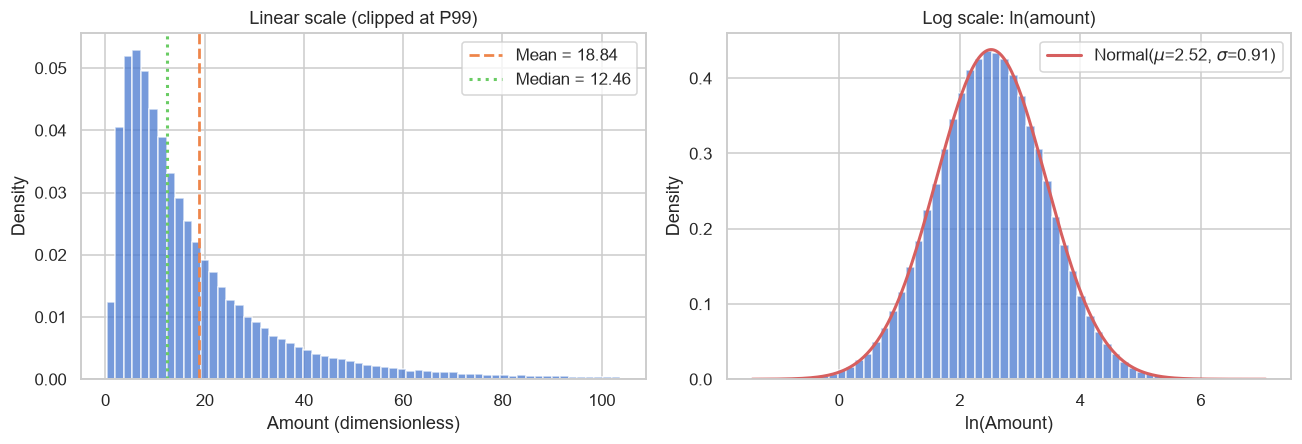

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Left: linear scale (clipped at P99 for visibility)
p99 = amt.quantile(0.99)
axes[0].hist(amt[amt <= p99], bins=60, density=True, alpha=0.75, edgecolor="white")
axes[0].axvline(amt.mean(), color="C1", ls="--", lw=1.8, label=f"Mean = {amt.mean():.2f}")
axes[0].axvline(amt.median(), color="C2", ls=":", lw=2.0, label=f"Median = {amt.median():.2f}")
axes[0].set_title("Linear scale (clipped at P99)")
axes[0].set_xlabel("Amount (dimensionless)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Right: log scale with fitted Normal overlay
mu_ln, sd_ln = log_amt.mean(), log_amt.std()
x_grid = np.linspace(log_amt.min(), log_amt.max(), 300)
axes[1].hist(log_amt, bins=60, density=True, alpha=0.75, edgecolor="white")
axes[1].plot(
    x_grid,
    stats.norm.pdf(x_grid, mu_ln, sd_ln),
    color="C3",
    lw=2.0,
    label=f"Normal($\\mu$={mu_ln:.2f}, $\\sigma$={sd_ln:.2f})",
)
axes[1].set_title("Log scale: ln(amount)")
axes[1].set_xlabel("ln(Amount)")
axes[1].set_ylabel("Density")
axes[1].legend()

fig.tight_layout()
save_figure("02_amount_distribution.png")

## 3. Entity Frequency & Overdispersion

Quantify card-level heterogeneity ($\text{Var}/\text{Mean} > 1$ and $\sigma_{\text{card}}$)
to explain the +2.46% volume gap between the probe forecast (204,162) and the actual
base dataset (209,185), and inspect merchant traffic concentration.

In [5]:
N_DAYS = 12
card_counts = df.groupby("card_id").size()
card_daily_rate = card_counts / N_DAYS
merchant_counts = df.groupby("merchant_id").size()

sigma_card = card_daily_rate.std()
se_probe_500 = sigma_card / np.sqrt(500)

entity_stats = pd.DataFrame(
    {
        "card_12d_tx": {
            "count_entities": len(card_counts),
            "mean": card_counts.mean(),
            "var": card_counts.var(),
            "var_to_mean": card_counts.var() / card_counts.mean(),
            "median": card_counts.median(),
            "p95": card_counts.quantile(0.95),
            "max": card_counts.max(),
        },
        "merchant_12d_tx": {
            "count_entities": len(merchant_counts),
            "mean": merchant_counts.mean(),
            "var": merchant_counts.var(),
            "var_to_mean": merchant_counts.var() / merchant_counts.mean(),
            "median": merchant_counts.median(),
            "p95": merchant_counts.quantile(0.95),
            "max": merchant_counts.max(),
        },
    }
).round(3)
display(entity_stats)

print(
    f"Empirical card daily rate: mean={card_daily_rate.mean():.4f} | "
    f"sigma_card={sigma_card:.4f} | SE(probe n=500)={se_probe_500:.4f} tx/card/day"
)

,card_12d_tx,merchant_12d_tx
count_entities,17500.000,4000.000
mean,11.953,52.296
var,17.861,179.011
var_to_mean,1.494,3.423
median,12.000,52.000
p95,19.000,74.000
max,34.000,96.000


Empirical card daily rate: mean=0.9961 | sigma_card=0.3522 | SE(probe n=500)=0.0158 tx/card/day


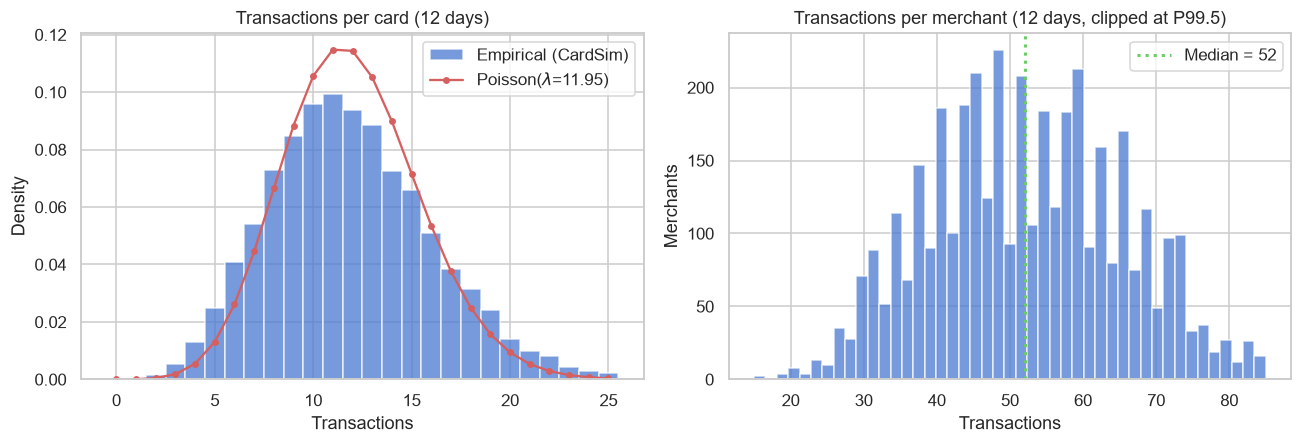

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Left: card 12-day count vs homogeneous Poisson with same mean
k_max = int(card_counts.quantile(0.995))
k_vals = np.arange(0, k_max + 1)
axes[0].hist(
    card_counts[card_counts <= k_max],
    bins=np.arange(0, k_max + 2) - 0.5,
    density=True,
    alpha=0.75,
    edgecolor="white",
    label="Empirical (CardSim)",
)
axes[0].plot(
    k_vals,
    stats.poisson.pmf(k_vals, card_counts.mean()),
    "o-",
    color="C3",
    ms=3.5,
    lw=1.5,
    label=f"Poisson($\\lambda$={card_counts.mean():.2f})",
)
axes[0].set_title("Transactions per card (12 days)")
axes[0].set_xlabel("Transactions")
axes[0].set_ylabel("Density")
axes[0].legend()

# Right: merchant 12-day count
m_max = int(merchant_counts.quantile(0.995))
axes[1].hist(merchant_counts[merchant_counts <= m_max], bins=45, alpha=0.75, edgecolor="white")
axes[1].axvline(merchant_counts.median(), color="C2", ls=":", lw=2.0, label=f"Median = {merchant_counts.median():.0f}")
axes[1].set_title("Transactions per merchant (12 days, clipped at P99.5)")
axes[1].set_xlabel("Transactions")
axes[1].set_ylabel("Merchants")
axes[1].legend()

fig.tight_layout()
save_figure("02_entity_frequency.png")

## 4. Temporal Patterns, Marginals & Distance by Channel

Check daily volume stability (no day-12 truncation), intraday seasonality, DCPC
marginals (`card_type`, `channel`), and whether `merchant_distance_km` behaves
differently for remote vs. in-person payments.

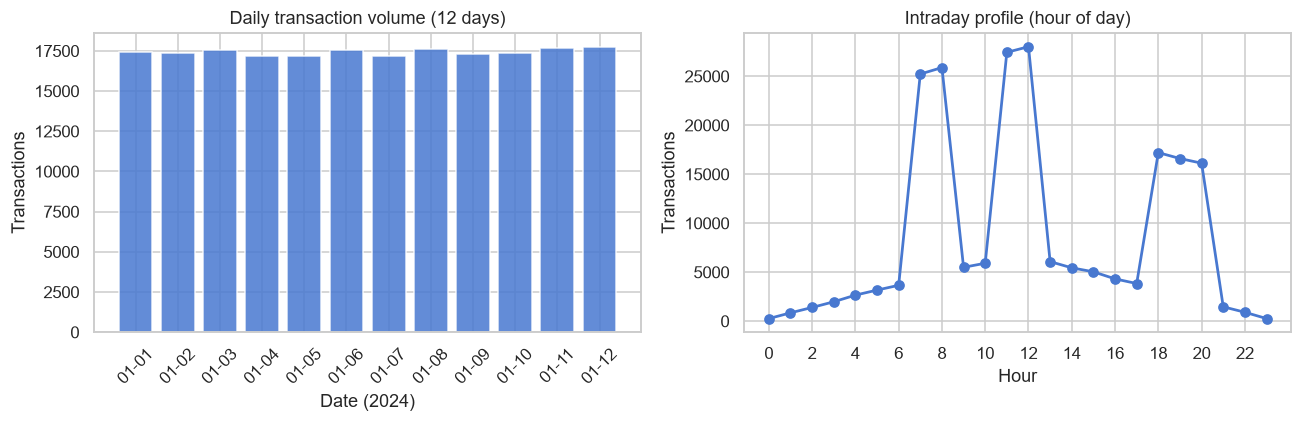

Card type shares: {'debit': 62.06, 'credit': 37.94}
Channel shares:   {'in_person': 64.06, 'remote': 35.94}


,count,median,iqr,p95,max
channel,,,,,
in_person,134006,73.379997,58.75,153.080002,253.460007
remote,75179,102.529999,50.00,166.710007,255.029999


In [7]:
daily_vol = df.set_index("transaction_timestamp").resample("D").size()
hourly_vol = df["transaction_timestamp"].dt.hour.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))

axes[0].bar(daily_vol.index.strftime("%m-%d"), daily_vol.values, alpha=0.85)
axes[0].set_title("Daily transaction volume (12 days)")
axes[0].set_xlabel("Date (2024)")
axes[0].set_ylabel("Transactions")
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(hourly_vol.index, hourly_vol.values, marker="o", lw=1.8)
axes[1].set_title("Intraday profile (hour of day)")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Transactions")
axes[1].set_xticks(range(0, 24, 2))

fig.tight_layout()
save_figure("02_temporal_patterns.png")

# Marginals & distance by channel
print("Card type shares:", (df["card_type"].value_counts(normalize=True) * 100).round(2).to_dict())
print("Channel shares:  ", (df["channel"].value_counts(normalize=True) * 100).round(2).to_dict())

dist_by_channel = (
    df.groupby("channel")["merchant_distance_km"]
    .agg(
        count="count",
        median="median",
        iqr=lambda s: s.quantile(0.75) - s.quantile(0.25),
        p95=lambda s: s.quantile(0.95),
        max="max",
    )
    .round(2)
)
display(dist_by_channel)

## 5. Baseline Fraud Profile & Injector Calibration Anchors

Characterize CardSim's conditionally independent baseline fraud (1.0015%) across
key dimensions and confirm the absence of coordinated multi-transaction bursts before
injecting **Card Testing** and **Bust-Out** campaigns.

In [8]:
# Conditional fraud rates
by_channel = df.groupby("channel")["is_fraud"].agg(tx="count", frauds="sum", rate="mean")
by_card = df.groupby("card_type")["is_fraud"].agg(tx="count", frauds="sum", rate="mean")
df_amt_q = pd.qcut(df["amount"], q=4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
by_amt_q = df.groupby(df_amt_q, observed=True)["is_fraud"].agg(tx="count", frauds="sum", rate="mean")

fraud_breakdown = pd.concat(
    {"channel": by_channel, "card_type": by_card, "amount_quartile": by_amt_q}
)
fraud_breakdown["rate_%"] = (fraud_breakdown["rate"] * 100).round(3)
display(fraud_breakdown[["tx", "frauds", "rate_%"]])

# Frauds per card distribution (checks independence / absence of coordinated bursts)
frauds_per_card = df.groupby("card_id")["is_fraud"].sum().value_counts().sort_index()
display(frauds_per_card.rename("cards").to_frame())

# Calibration anchors for downstream campaign injectors
calibration_anchors = pd.DataFrame(
    [
        ("Card Testing amount (low probe)",  f"<= {amt.quantile(0.05):.2f}", "Baseline P05 of amount"),
        ("Typical payment (median)",         f"{amt.median():.2f}",         "Baseline P50 of amount"),
        ("Bust-Out amount (high spike)",     f">= {amt.quantile(0.99):.2f}", "Baseline P99 of amount"),
        ("Normal card velocity",             f"{card_daily_rate.mean():.2f} tx/day", "Mean daily rate"),
        ("High-activity card (P99)",         f"{card_daily_rate.quantile(0.99):.2f} tx/day", "P99 daily rate"),
    ],
    columns=["Anchor", "Value", "Basis"],
).set_index("Anchor")
display(calibration_anchors)

tx  frauds  rate_%
channel         in_person  134006     528   0.394
                remote      75179    1567   2.084
card_type       credit      79374    1420   1.789
                debit      129811     675   0.520
amount_quartile Q1 (low)    52297      18   0.034
                Q2          52296     102   0.195
                Q3          52296     297   0.568
                Q4 (high)   52296    1678   3.209

,cards
is_fraud,
0,15540
1,1828
2,129
3,3


,Value,Basis
Anchor,,
Card Testing amount (low probe),<= 2.78,Baseline P05 of amount
Typical payment (median),12.46,Baseline P50 of amount
Bust-Out amount (high spike),>= 103.70,Baseline P99 of amount
Normal card velocity,1.00 tx/day,Mean daily rate
High-activity card (P99),1.92 tx/day,P99 daily rate
